In [2]:
!pip install qiskit qiskit-optimization qiskit-algorithms networkx matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 3.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 40.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.1/237.1 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 74.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.3 MB/s eta 0:00:00
  Created wheel for docplex: filename=docplex-2.32.264-py3-none-any.whl size=703859 sha256=54e1b0618434936b7a8da6dc112b7e3e50b3fe694e298a3fdc7bdea3e90105cd
  Stored in directory: /root/.cache/pip/wheels/ba/11/de/5d0051be010658975fb2155006b4b8a818136d9f69ed20b4ba
Successfully built docplex


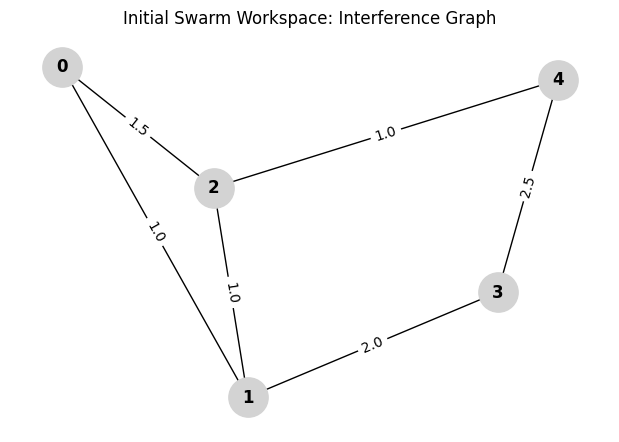

--- Classical Quadratic Formulation ---
\ This file has been generated by DOcplex
\ ENCODING=ISO-8859-1
\Problem name: Max-cut

Maximize
 obj: 2.500000000000 x_0 + 4 x_1 + 3.500000000000 x_2 + 4.500000000000 x_3
      + 3.500000000000 x_4 + [ - 4 x_0*x_1 - 6 x_0*x_2 - 4 x_1*x_2 - 8 x_1*x_3
      - 4 x_2*x_4 - 10 x_3*x_4 ]/2
Subject To

Bounds
 0 <= x_0 <= 1
 0 <= x_1 <= 1
 0 <= x_2 <= 1
 0 <= x_3 <= 1
 0 <= x_4 <= 1

Binaries
 x_0 x_1 x_2 x_3 x_4
End


--- Quantum Ising Hamiltonian ---
SparsePauliOp(['IIIZZ', 'IIZIZ', 'IIZZI', 'IZIZI', 'ZIZII', 'ZZIII'],
              coeffs=[0.5 +0.j, 0.75+0.j, 0.5 +0.j, 1.  +0.j, 0.5 +0.j, 1.25+0.j])


/tmp/ipykernel_1999/728944162.py:44: DeprecationWarning: The method ``qiskit_optimization.problems.quadratic_program.QuadraticProgram.export_as_lp_string()`` is deprecated as of Qiskit 0.7.0. It will be removed no earlier than 3 months after the release date. Use prettyprint instead.
  print(qp.export_as_lp_string())


In [3]:
import networkx as nx
import matplotlib.pyplot as plt
from qiskit_optimization.applications import Maxcut

# ==========================================
# STEP 1: Build the Classical Spatial Graph
# ==========================================
# Nodes = Target task locations (0 through 4)
# Edges = Spatial interference penalty if tasks are assigned to the same robot
num_tasks = 5
workspace_graph = nx.Graph()
workspace_graph.add_nodes_from(range(num_tasks))

# (node_i, node_j, penalty_weight)
# Higher weight means these tasks are too close together
interference_edges = [
    (0, 1, 1.0),
    (0, 2, 1.5),
    (1, 2, 1.0),
    (1, 3, 2.0),
    (2, 4, 1.0),
    (3, 4, 2.5)
]
workspace_graph.add_weighted_edges_from(interference_edges)

# Draw the initial workspace
plt.figure(figsize=(6, 4))
pos = nx.spring_layout(workspace_graph, seed=42) # Fixed seed for consistent drawing
nx.draw(workspace_graph, pos, with_labels=True, node_color='lightgrey', node_size=800, font_weight='bold')
labels = nx.get_edge_attributes(workspace_graph, 'weight')
nx.draw_networkx_edge_labels(workspace_graph, pos, edge_labels=labels)
plt.title("Initial Swarm Workspace: Interference Graph")
plt.show()

# ==========================================
# STEP 2: Map to a Quantum Problem
# ==========================================
# Initialize the Max-Cut application using our graph
max_cut = Maxcut(workspace_graph)

# Translate to a classical Quadratic Program
qp = max_cut.to_quadratic_program()
print("--- Classical Quadratic Formulation ---")
print(qp.export_as_lp_string())

# Translate to a Quantum Ising Hamiltonian
qubit_op, offset = qp.to_ising()
print("\n--- Quantum Ising Hamiltonian ---")
print(qubit_op)


In [5]:
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit.primitives import StatevectorSampler # <--- This is the updated import
from qiskit_optimization.algorithms import MinimumEigenOptimizer

# ==========================================
# STEP 3: Run the QAOA Solver
# ==========================================
# 1. Setup the QAOA algorithm components using the new StatevectorSampler
sampler = StatevectorSampler()
optimizer = COBYLA(maxiter=100)
qaoa = QAOA(sampler=sampler, optimizer=optimizer, reps=2)

# 2. Wrap QAOA to solve optimization problems
vqe_optimizer = MinimumEigenOptimizer(qaoa)

# 3. Solve the Quadratic Program (qp) we built in Step 2
print("Running QAOA on the quantum simulator... please wait a moment.")
result = vqe_optimizer.solve(qp)

# 4. Parse and display the results
print("\n--- Optimization Results ---")
print(f"Optimal Bitstring: {result.x}")

robot_a_tasks = [i for i, val in enumerate(result.x) if val == 0]
robot_b_tasks = [i for i, val in enumerate(result.x) if val == 1]

print(f"\nNodes assigned to Robot A: {robot_a_tasks}")
print(f"Nodes assigned to Robot B: {robot_b_tasks}")

Running QAOA on the quantum simulator... please wait a moment.


/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])



--- Optimization Results ---
Optimal Bitstring: [0. 0. 1. 1. 0.]

Nodes assigned to Robot A: [0, 1, 4]
Nodes assigned to Robot B: [2, 3]


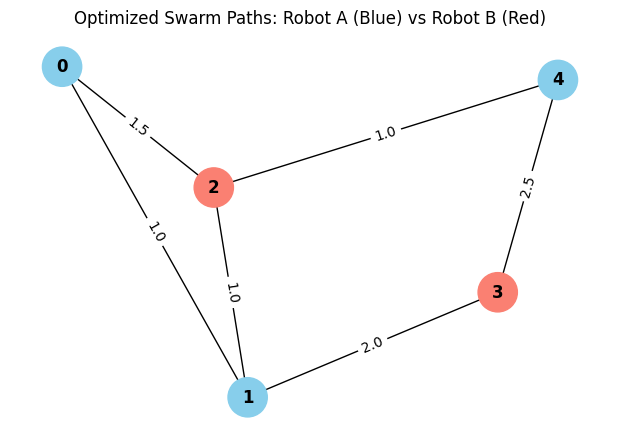

In [6]:
# ==========================================
# STEP 4: Visualize the Solution
# ==========================================
# Map the quantum result bitstring to colors for our two robots
node_colors = []
for node in workspace_graph.nodes:
    if result.x[node] == 0:
        node_colors.append('skyblue') # Robot A
    else:
        node_colors.append('salmon')  # Robot B

plt.figure(figsize=(6, 4))
# Re-use the exact same layout from Step 1 so the graph shape matches perfectly
pos = nx.spring_layout(workspace_graph, seed=42)

# Draw the partitioned graph
nx.draw(workspace_graph, pos, with_labels=True, node_color=node_colors, node_size=800, font_weight='bold')
labels = nx.get_edge_attributes(workspace_graph, 'weight')
nx.draw_networkx_edge_labels(workspace_graph, pos, edge_labels=labels)

plt.title("Optimized Swarm Paths: Robot A (Blue) vs Robot B (Red)")
plt.show()

In [7]:
from qiskit_algorithms import NumPyMinimumEigensolver
from qiskit_optimization.algorithms import MinimumEigenOptimizer

# ==========================================
# STEP 5: Classical Baseline Comparison
# ==========================================
# The hackathon rules require a classical baseline comparison.
# We will use a classical brute-force exact solver to verify our QAOA result.

exact_solver = NumPyMinimumEigensolver()
exact_optimizer = MinimumEigenOptimizer(exact_solver)
exact_result = exact_optimizer.solve(qp)

print("--- Baseline Comparison ---")
print(f"Quantum QAOA Bitstring:     {result.x}")
print(f"Classical Exact Bitstring:  {exact_result.x}")

if (result.x == exact_result.x).all():
    print("\nSuccess! The quantum algorithm matched the perfect classical baseline.")
else:
    print("\nThe QAOA solution differs from the exact baseline (common with low-depth quantum approximations).")

--- Baseline Comparison ---
Quantum QAOA Bitstring:     [0. 0. 1. 1. 0.]
Classical Exact Bitstring:  [0. 0. 1. 1. 0.]

Success! The quantum algorithm matched the perfect classical baseline.
